# Práctica 1
Manuel Suano Gallardo

Este notebook lo he creado a partir del notebook proporcionado para la práctica.
Tiene el mismo código, solo que reorganizado para que quede más claro las partes
que modifico para cumplir los requisitos de la práctica.

## Código no variable

En esta sección voy a poner en una misma celda todo el código del notebook 
`vae_keras3.ipynb` que no voy a modificar. Estará en el mismo orden.

In [54]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import tensorflow as tf
import keras
from keras import ops
from keras import layers

import matplotlib.pyplot as plt

from tensorflow.python.client import device_lib
def get_available_gpus():
	local_device_protos = device_lib.list_local_devices()
	return [x.name for x in local_device_protos if x.device_type == 'GPU']

print("Available GPUs ")
get_available_gpus()

################################################################################
# Capa de sampling

class Sampling(layers.Layer):
	"""Uses (z_mean, z_log_var) to sample z, the vector encoding a digit."""

	def __init__(self, **kwargs):
		super().__init__(**kwargs)
		self.seed_generator = keras.random.SeedGenerator(42)

	def call(self, inputs):
		z_mean, z_log_var = inputs
		#batch = ops.shape(z_mean)[0]
		#dim = ops.shape(z_mean)[1]
		batch = ops.shape(z_log_var)[0]
		dim = ops.shape(z_log_var)[1]
		epsilon = keras.random.normal(shape=(batch, dim), seed=self.seed_generator)
		return z_mean + ops.exp(0.5 * z_log_var) * epsilon
	
################################################################################
# Codificador

tf.random.set_seed(42)  # extra code – ensures reproducibility on CPU

codings_size = 10
encoder_inputs = keras.layers.Input(shape=[28, 28])
x = layers.Flatten()(encoder_inputs)
x = layers.Dense(150, activation="relu")(x)
x = layers.Dense(100, activation="relu")(x)
z_mean = layers.Dense(codings_size, name="z_mean")(x)
z_log_var = layers.Dense(codings_size, name="z_log_var")(x)
variational_encoder = keras.Model([encoder_inputs], [z_mean, z_log_var], name="encoder")
variational_encoder.summary()

################################################################################
# Decodificador

latent_inputs = keras.layers.Input(shape=(codings_size,))
x = tf.keras.layers.Dense(100, activation="relu")(latent_inputs)
x = tf.keras.layers.Dense(150, activation="relu")(x)
x = tf.keras.layers.Dense(28 * 28)(x)
outputs = tf.keras.layers.Reshape([28, 28])(x)
variational_decoder = keras.Model(latent_inputs, outputs, name="decoder")
variational_decoder.summary()

################################################################################
# Datos de MNIST

fashion_mnist = keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train_full = X_train_full.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

################################################################################
# Mostrar las imágenes

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

# En esta función he eliminado el valor por defecto de "images", ya que era la 
# variable X_valid que, en este punto, no está definida. También he eliminado
# la generación de predicciones y he indicado como parámetro las predicciones.
def plot_reconstructions(images, predictions, n_images=5):
	reconstructions = np.clip(predictions, 0, 1)
	fig = plt.figure(figsize=(n_images * 1.5, 3))
	for image_index in range(n_images):
		plt.subplot(2, n_images, 1 + image_index)
		plt.imshow(images[image_index], cmap="binary")
		plt.axis("off")
		plt.subplot(2, n_images, 1 + n_images + image_index)
		plt.imshow(reconstructions[image_index], cmap="binary")        
		plt.axis("off")

Available GPUs 


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 28, 28)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 784)       │          0 │ input_layer_6[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 150)       │    117,750 │ flatten_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 100)       │     15,100 │ dense_15[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 10)        │      1,010 │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 10)        │      1,010 │ dense_16[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 134,870 (526.84 KB)

 Trainable params: 134,870 (526.84 KB)

...

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 100)            │         1,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 150)            │        15,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 784)            │       118,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 28, 28)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,634 (525.91 KB)

 Trainable params: 134,634 (525.91 KB)

 Non-trainable params: 0 (0.00 B)

## Clase VAE

Sobre esta clase se realizarán algunas de los cambios requeridos en la práctica.
Estos cambios estarán divididos del código original caracteres `#`.

In [2]:
class VAE(keras.Model):
	def __init__(self, encoder, decoder, **kwargs):
		
		super().__init__(**kwargs)
		self.encoder = encoder
		self.decoder = decoder
		self.sampling = Sampling()
		self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
		self.reconstruction_loss_tracker = keras.metrics.Mean(
			name="reconstruction_loss"
		)
		self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")
		
		# ########################################
		# Atributo "beta". Por defecto el modelo es un VAE
		self.beta = 1
		# ########################################

	@property
	def metrics(self):
		return [
			self.total_loss_tracker,
			self.reconstruction_loss_tracker,
			self.kl_loss_tracker,
		]
	
	# ########################################
	# Función para dar valor a "beta"
	def set_beta(self, valor):
		if valor < 0:
			raise RuntimeError('El valor de beta no puede ser menor que 0')
		else:
			self.beta = valor
	# ########################################

	def train_step(self, data):
		x, y = data
		with tf.GradientTape() as tape:
			z_mean, z_log_var = self.encoder(x) # en el libro codings_mean y codings_log_var
			z = self.sampling([z_mean, z_log_var]) # en el libro codings
			reconstruction = self.decoder(z)
			
			# MSE loss
			reconstruction_loss = tf.keras.ops.mean(tf.keras.ops.square(x - reconstruction))

			# Pérdida latente
			kl_loss = -0.5 * (1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var))
			kl_loss = ops.mean(ops.sum(kl_loss, axis=1))            

			# ########################################
			# Adición del atributo "beta" al calculo de la pérdida total. 
			# Simplemente hay que multiplicar el segundo atributo, que es el que
			# usa la pérdida latente y, por tanto, el que hace que sea una VAE,
			# por el valor que tenga el atributo "beta"
			total_loss = reconstruction_loss + self.beta * tf.keras.ops.mean(kl_loss)/784.
			# ########################################

		grads = tape.gradient(total_loss, self.trainable_weights)
		self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
		self.total_loss_tracker.update_state(total_loss)
		self.reconstruction_loss_tracker.update_state(reconstruction_loss)
		self.kl_loss_tracker.update_state(kl_loss)
		return {
			"loss": self.total_loss_tracker.result(),
			"reconstruction_loss": self.reconstruction_loss_tracker.result(),
			"kl_loss": self.kl_loss_tracker.result(),
		}
		
	def test_step(self, data): 
		X, y = data
		y_pred = self(X, training=False)
		
		for metric in self.metrics:
			metric.update_state(y, y_pred)
		return {m.name: m.result() for m in self.metrics}        
		
	def call(self, inputs, *args, **kwargs):
		# Used for inference/prediction
		z_mean, z_log_var = self.encoder(inputs)
		z = self.sampling([z_mean, z_log_var])
		return self.decoder(z)        

## Entrenamiento de la red

Se creará un modelo VAE por cada uno de las 6 posibilidades que se plantean en la
práctica para el valor de beta.

In [3]:
tf.random.set_seed(42)

# Beta = 0
vae_0 = VAE(
    # Se clonan los modelos en su estado original para que cada modelo VAE tenga
    # uno propio
    keras.models.clone_model(variational_encoder), 
    keras.models.clone_model(variational_decoder)
)
vae_0.set_beta(0) # Se añade el valor beta
vae_0.compile(optimizer=keras.optimizers.Nadam())

# Beta = 1
vae_1 = VAE(
    keras.models.clone_model(variational_encoder), 
    keras.models.clone_model(variational_decoder)
)
vae_1.set_beta(1)
vae_1.compile(optimizer=keras.optimizers.Nadam())

# Beta entre 0 y 1 (= 0.5)
vae_0_1 = VAE(
    keras.models.clone_model(variational_encoder), 
    keras.models.clone_model(variational_decoder)
)
vae_0_1.set_beta(0.5)
vae_0_1.compile(optimizer=keras.optimizers.Nadam())

# Beta > 1 (= 2)
vae_gt_1_2 = VAE(
    keras.models.clone_model(variational_encoder), 
    keras.models.clone_model(variational_decoder)
)
vae_gt_1_2.set_beta(2)
vae_gt_1_2.compile(optimizer=keras.optimizers.Nadam())

# Beta > 1 (= 6)
vae_gt_1_6 = VAE(
    keras.models.clone_model(variational_encoder), 
    keras.models.clone_model(variational_decoder)
)
vae_gt_1_6.set_beta(6)
vae_gt_1_6.compile(optimizer=keras.optimizers.Nadam())

# Beta > 1 (= 15)
vae_gt_1_15 = VAE(
    keras.models.clone_model(variational_encoder), 
    keras.models.clone_model(variational_decoder)
)
vae_gt_1_15.set_beta(15)
vae_gt_1_15.compile(optimizer=keras.optimizers.Nadam())

A continuación, se entrenan los modelos con los mismos parámetros que están 
indicados en el notebook proporcionado.

In [4]:
history_0 = vae_0.fit(
    X_train, X_train, epochs=25, batch_size=128, validation_data=(X_valid, X_valid)
)

Epoch 1/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - kl_loss: 96.1767 - loss: 0.0335 - reconstruction_loss: 0.0335 - val_kl_loss: 0.6436 - val_reconstruction_loss: 0.6436 - val_total_loss: 0.6436
Epoch 2/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 142.4854 - loss: 0.0205 - reconstruction_loss: 0.0205 - val_kl_loss: 0.6477 - val_reconstruction_loss: 0.6477 - val_total_loss: 0.6477
Epoch 3/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 154.9650 - loss: 0.0188 - reconstruction_loss: 0.0188 - val_kl_loss: 0.6565 - val_reconstruction_loss: 0.6565 - val_total_loss: 0.6565
Epoch 4/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 162.0850 - loss: 0.0179 - reconstruction_loss: 0.0179 - val_kl_loss: 0.6619 - val_reconstruction_loss: 0.6619 - val_total_loss: 0.6619
Epoch 5/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 166.6153 - loss: 0.0173 - reconstruction_loss: 0.0173 - val_kl_loss: 0.6599 - val_reconstruction_loss: 0.6599 - val_total_loss: 0.6599
Epoch 6/25


In [5]:
history_1 = vae_1.fit(
    X_train, X_train, epochs=25, batch_size=128, validation_data=(X_valid, X_valid)
)

Epoch 1/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - kl_loss: 6.6969 - loss: 0.0497 - reconstruction_loss: 0.0411 - val_kl_loss: 0.6193 - val_reconstruction_loss: 0.6193 - val_total_loss: 0.6193
Epoch 2/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 6.5975 - loss: 0.0364 - reconstruction_loss: 0.0280 - val_kl_loss: 0.6342 - val_reconstruction_loss: 0.6342 - val_total_loss: 0.6342
Epoch 3/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 6.6453 - loss: 0.0347 - reconstruction_loss: 0.0262 - val_kl_loss: 0.6384 - val_reconstruction_loss: 0.6384 - val_total_loss: 0.6384
Epoch 4/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 6.7533 - loss: 0.0338 - reconstruction_loss: 0.0252 - val_kl_loss: 0.6390 - val_reconstruction_loss: 0.6390 - val_total_loss: 0.6390
Epoch 5/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 6.8608 - loss: 0.0333 - reconstruction_loss: 0.0245 - val_kl_loss: 0.6352 - val_reconstruction_loss: 0.6352 - val_total_loss: 0.6352
Epoch 6/25
430/430 ━

In [6]:
history_0_1 = vae_0_1.fit(
    X_train, X_train, epochs=25, batch_size=128, validation_data=(X_valid, X_valid)
)

Epoch 1/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - kl_loss: 10.4284 - loss: 0.0438 - reconstruction_loss: 0.0372 - val_kl_loss: 0.6323 - val_reconstruction_loss: 0.6323 - val_total_loss: 0.6323
Epoch 2/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 10.1943 - loss: 0.0311 - reconstruction_loss: 0.0246 - val_kl_loss: 0.6390 - val_reconstruction_loss: 0.6390 - val_total_loss: 0.6390
Epoch 3/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 10.3461 - loss: 0.0291 - reconstruction_loss: 0.0225 - val_kl_loss: 0.6434 - val_reconstruction_loss: 0.6434 - val_total_loss: 0.6434
Epoch 4/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 10.3718 - loss: 0.0282 - reconstruction_loss: 0.0216 - val_kl_loss: 0.6472 - val_reconstruction_loss: 0.6472 - val_total_loss: 0.6472
Epoch 5/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 10.4047 - loss: 0.0277 - reconstruction_loss: 0.0210 - val_kl_loss: 0.6484 - val_reconstruction_loss: 0.6484 - val_total_loss: 0.6484
Epoch 6/25
430/

In [7]:
history_gt_1_2 = vae_gt_1_2.fit(
    X_train, X_train, epochs=25, batch_size=128, validation_data=(X_valid, X_valid)
)

Epoch 1/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - kl_loss: 4.3138 - loss: 0.0571 - reconstruction_loss: 0.0460 - val_kl_loss: 0.6079 - val_reconstruction_loss: 0.6079 - val_total_loss: 0.6079
Epoch 2/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 4.5653 - loss: 0.0437 - reconstruction_loss: 0.0321 - val_kl_loss: 0.6187 - val_reconstruction_loss: 0.6187 - val_total_loss: 0.6187
Epoch 3/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 4.6321 - loss: 0.0419 - reconstruction_loss: 0.0301 - val_kl_loss: 0.6234 - val_reconstruction_loss: 0.6234 - val_total_loss: 0.6234
Epoch 4/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 4.7041 - loss: 0.0411 - reconstruction_loss: 0.0291 - val_kl_loss: 0.6238 - val_reconstruction_loss: 0.6238 - val_total_loss: 0.6238
Epoch 5/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 4.7542 - loss: 0.0406 - reconstruction_loss: 0.0285 - val_kl_loss: 0.6219 - val_reconstruction_loss: 0.6219 - val_total_loss: 0.6219
Epoch 6/25
430/430 ━

In [8]:
history_gt_1_6 = vae_gt_1_6.fit(
    X_train, X_train, epochs=25, batch_size=128, validation_data=(X_valid, X_valid)
)

Epoch 1/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - kl_loss: 1.7438 - loss: 0.0729 - reconstruction_loss: 0.0596 - val_kl_loss: 0.5625 - val_reconstruction_loss: 0.5625 - val_total_loss: 0.5625
Epoch 2/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 2.2059 - loss: 0.0611 - reconstruction_loss: 0.0442 - val_kl_loss: 0.5757 - val_reconstruction_loss: 0.5757 - val_total_loss: 0.5757
Epoch 3/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 2.3028 - loss: 0.0597 - reconstruction_loss: 0.0421 - val_kl_loss: 0.5808 - val_reconstruction_loss: 0.5808 - val_total_loss: 0.5808
Epoch 4/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 2.3676 - loss: 0.0591 - reconstruction_loss: 0.0410 - val_kl_loss: 0.5815 - val_reconstruction_loss: 0.5815 - val_total_loss: 0.5815
Epoch 5/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 2.4092 - loss: 0.0587 - reconstruction_loss: 0.0403 - val_kl_loss: 0.5867 - val_reconstruction_loss: 0.5867 - val_total_loss: 0.5867
Epoch 6/25
430/430 ━

In [9]:
history_gt_1_15 = vae_gt_1_15.fit(
    X_train, X_train, epochs=25, batch_size=128, validation_data=(X_valid, X_valid)
)

Epoch 1/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - kl_loss: 0.4064 - loss: 0.0881 - reconstruction_loss: 0.0803 - val_kl_loss: 0.4959 - val_reconstruction_loss: 0.4959 - val_total_loss: 0.4959
Epoch 2/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 0.8126 - loss: 0.0792 - reconstruction_loss: 0.0636 - val_kl_loss: 0.5138 - val_reconstruction_loss: 0.5138 - val_total_loss: 0.5138
Epoch 3/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 0.9082 - loss: 0.0779 - reconstruction_loss: 0.0605 - val_kl_loss: 0.5174 - val_reconstruction_loss: 0.5174 - val_total_loss: 0.5174
Epoch 4/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 0.9521 - loss: 0.0777 - reconstruction_loss: 0.0595 - val_kl_loss: 0.5168 - val_reconstruction_loss: 0.5168 - val_total_loss: 0.5168
Epoch 5/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 0.9550 - loss: 0.0774 - reconstruction_loss: 0.0591 - val_kl_loss: 0.5204 - val_reconstruction_loss: 0.5204 - val_total_loss: 0.5204
Epoch 6/25
430/430 ━

## Generación de las predicciones y cálculo SSIM

Se generan las predicciones y el cálculo del SSIM de las 50 primeras instancias
del conjunto X_valid.

In [10]:
X_valid_50 = X_valid[:50]

predicciones_0 = vae_0.predict(X_valid_50)
predicciones_1 = vae_1.predict(X_valid_50)
predicciones_0_1 = vae_0_1.predict(X_valid_50)
predicciones_gt_1_2 = vae_gt_1_2.predict(X_valid_50)
predicciones_gt_1_6 = vae_gt_1_6.predict(X_valid_50)
predicciones_gt_1_15 = vae_gt_1_15.predict(X_valid_50)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x0000020BC83F5A80> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


Para poder usar la función `tf.image.ssim` es necesario añadir a las imágenes el 
canal. En nuestro caso, al ser imágenes en escala de grises solo habrá un canal,
por lo que habrá que añadir una dimensión a los datos para pasar de (50, 28, 28)
a (50, 28, 28, 1).

In [ ]:
# Se añade una dimensión al final de las matrices tridimensionales
X_valid_50_canal = np.expand_dims(X_valid_50, axis=-1)
predicciones_0_canal = np.expand_dims(predicciones_0, axis=-1)
predicciones_1_canal = np.expand_dims(predicciones_1, axis=-1)
predicciones_0_1_canal = np.expand_dims(predicciones_0_1, axis=-1)
predicciones_gt_1_2_canal = np.expand_dims(predicciones_gt_1_2, axis=-1)
predicciones_gt_1_6_canal = np.expand_dims(predicciones_gt_1_6, axis=-1)
predicciones_gt_1_15_canal = np.expand_dims(predicciones_gt_1_15, axis=-1)

A partir de los datos originales y las predicciones calculamos la media y 
desviación típica del SSIM para cada valor de beta.

In [24]:
ssim_0 = tf.image.ssim(X_valid_50_canal, predicciones_0_canal, max_val=1).numpy()
ssim_1 = tf.image.ssim(X_valid_50_canal, predicciones_1_canal, max_val=1).numpy()
ssim_0_1 = tf.image.ssim(X_valid_50_canal, predicciones_0_1_canal, max_val=1).numpy()
ssim_gt_1_2 = tf.image.ssim(X_valid_50_canal, predicciones_gt_1_2_canal, max_val=1).numpy()
ssim_gt_1_6 = tf.image.ssim(X_valid_50_canal, predicciones_gt_1_6_canal, max_val=1).numpy()
ssim_gt_1_15 = tf.image.ssim(X_valid_50_canal, predicciones_gt_1_15_canal, max_val=1).numpy()


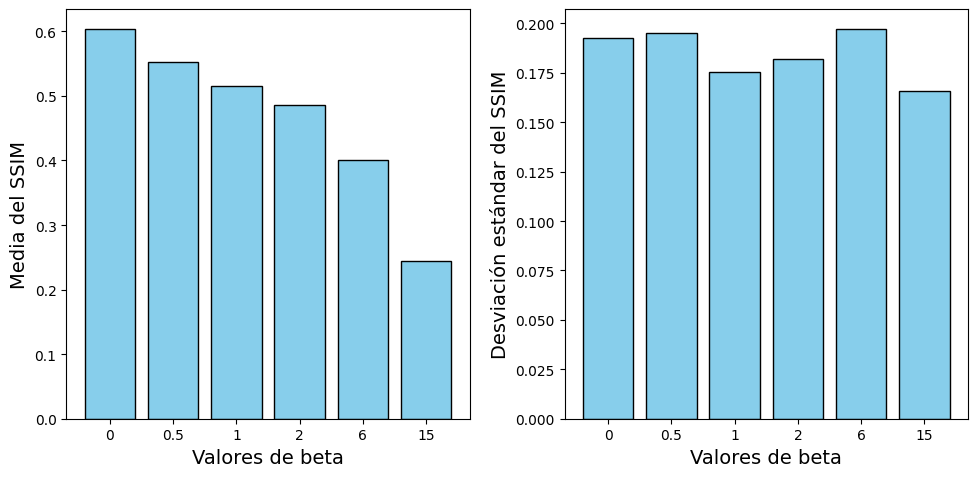

In [25]:
valores_beta = ["0", "0.5", "1", "2", "6", "15"]

medias_beta = [
    ssim_0.mean(), ssim_0_1.mean(), ssim_1.mean(), 
    ssim_gt_1_2.mean(), ssim_gt_1_6.mean(), ssim_gt_1_15.mean()
]

std_beta = [
    ssim_0.std(), ssim_0_1.std(), ssim_1.std(), 
    ssim_gt_1_2.std(), ssim_gt_1_6.std(), ssim_gt_1_15.std()
]

# Mostramos en una gráfica de barras la evolución de ambos valores
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.bar(valores_beta, medias_beta, color='skyblue', edgecolor='black')
ax1.set_xlabel('Valores de beta')
ax1.set_ylabel('Media del SSIM')

ax2.bar(valores_beta, std_beta, color='skyblue', edgecolor='black')
ax2.set_xlabel('Valores de beta')
ax2.set_ylabel('Desviación estándar del SSIM')

plt.tight_layout()
plt.show()

Por los resultados obtenidos, el valor de beta que genera mayor SSIM es 0.

## Uso de otros optimizadores

Para este caso se van a comprobar dos optimizadores: el histórico SGD y el 
ampliamente utilizado Adam. Se crean dos nuevos modelos y se siguen los mismos 
pasos que se han hecho anteriormente para calcular el SSIM.

In [30]:
vae_0_adam = VAE(
    keras.models.clone_model(variational_encoder), 
    keras.models.clone_model(variational_decoder)
)
vae_0_adam.set_beta(0)
vae_0_adam.compile(optimizer=keras.optimizers.Adam())

history_0_adam = vae_0_adam.fit(
    X_train, X_train, epochs=25, batch_size=128, validation_data=(X_valid, X_valid)
)

predicciones_0_adam = vae_0_adam.predict(X_valid_50)
predicciones_0_adam_canal = np.expand_dims(predicciones_0_adam, axis=-1)
ssim_0_adam = tf.image.ssim(X_valid_50_canal, predicciones_0_adam_canal, max_val=1).numpy()

Epoch 1/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - kl_loss: 82.7557 - loss: 0.0339 - reconstruction_loss: 0.0339 - val_kl_loss: 0.6474 - val_reconstruction_loss: 0.6474 - val_total_loss: 0.6474
Epoch 2/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 126.0557 - loss: 0.0204 - reconstruction_loss: 0.0204 - val_kl_loss: 0.6576 - val_reconstruction_loss: 0.6576 - val_total_loss: 0.6576
Epoch 3/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 133.2597 - loss: 0.0187 - reconstruction_loss: 0.0187 - val_kl_loss: 0.6591 - val_reconstruction_loss: 0.6591 - val_total_loss: 0.6591
Epoch 4/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - kl_loss: 136.5860 - loss: 0.0177 - reconstruction_loss: 0.0177 - val_kl_loss: 0.6608 - val_reconstruction_loss: 0.6608 - val_total_loss: 0.6608
Epoch 5/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 137.3911 - loss: 0.0171 - reconstruction_loss: 0.0171 - val_kl_loss: 0.6619 - val_reconstruction_loss: 0.6619 - val_total_loss: 0.6619
Epoch 6/25


In [31]:
vae_0_sgd = VAE(
    keras.models.clone_model(variational_encoder), 
    keras.models.clone_model(variational_decoder)
)
vae_0_sgd.set_beta(0)
vae_0_sgd.compile(optimizer=keras.optimizers.SGD())

history_0_sgd = vae_0_sgd.fit(
    X_train, X_train, epochs=25, batch_size=128, validation_data=(X_valid, X_valid)
)

predicciones_0_sgd = vae_0_sgd.predict(X_valid_50)
predicciones_0_sgd_canal = np.expand_dims(predicciones_0_sgd, axis=-1)
ssim_0_sgd = tf.image.ssim(X_valid_50_canal, predicciones_0_sgd_canal, max_val=1).numpy()

Epoch 1/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 0.8112 - loss: 0.2150 - reconstruction_loss: 0.2150 - val_kl_loss: 0.5366 - val_reconstruction_loss: 0.5366 - val_total_loss: 0.5366
Epoch 2/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 0.8150 - loss: 0.2031 - reconstruction_loss: 0.2031 - val_kl_loss: 0.4670 - val_reconstruction_loss: 0.4670 - val_total_loss: 0.4670
Epoch 3/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - kl_loss: 1.1568 - loss: 0.1940 - reconstruction_loss: 0.1940 - val_kl_loss: 0.4567 - val_reconstruction_loss: 0.4567 - val_total_loss: 0.4567
Epoch 4/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 2.2178 - loss: 0.1829 - reconstruction_loss: 0.1829 - val_kl_loss: 0.4643 - val_reconstruction_loss: 0.4643 - val_total_loss: 0.4643
Epoch 5/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 5.7247 - loss: 0.1622 - reconstruction_loss: 0.1622 - val_kl_loss: 0.4824 - val_reconstruction_loss: 0.4824 - val_total_loss: 0.4824
Epoch 6/25
430/430 ━

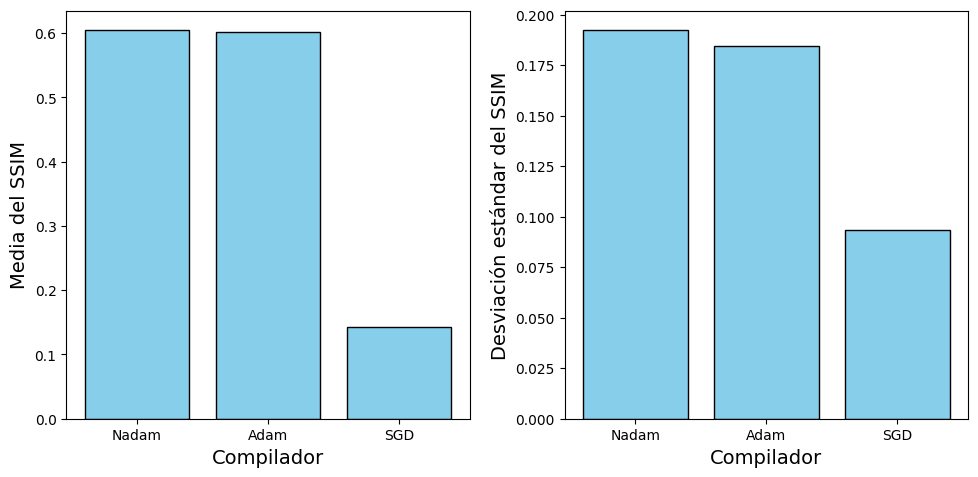

In [32]:
compiladores = ['Nadam', 'Adam', 'SGD']
medias_ssim_0 = [ssim_0.mean(), ssim_0_adam.mean(), ssim_0_sgd.mean()]
std_ssim_0 = [ssim_0.std(), ssim_0_adam.std(), ssim_0_sgd.std()]

# Mostramos en una gráfica de barras la evolución de ambos valores
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.bar(compiladores, medias_ssim_0, color='skyblue', edgecolor='black')
ax1.set_xlabel('Compilador')
ax1.set_ylabel('Media del SSIM')

ax2.bar(compiladores, std_ssim_0, color='skyblue', edgecolor='black')
ax2.set_xlabel('Compilador')
ax2.set_ylabel('Desviación estándar del SSIM')

plt.tight_layout()
plt.show()

In [33]:
print(ssim_0.mean(), ssim_0_adam.mean())

0.60443914 0.60078424


Entre los tres compiladores, Nadam y Adam consiguen resultados muy parejos en la
media del SSIM, siendo Nadam ligeramente superior, por lo que tomaremos ese 
compilador para la búsqueda del mejor ratio de aprendizaje.

## Búsqueda del ratio de aprendizaje

Para la búsqueda del mejor ratio de aprendizaje utilizaré la clase proporcionada
en la asignatura Aprendizaje Automático 1, en la práctica 2.

In [34]:
class ExponentialLearningRate(tf.keras.callbacks.Callback):
	def __init__(self, factor):
		self.factor = factor
		self.rates = []
		self.losses = []

	def on_batch_end(self, batch, logs=None):
		lr = self.model.optimizer.learning_rate.numpy() * self.factor
		self.model.optimizer.learning_rate = lr
		self.rates.append(lr)
		self.losses.append(logs["loss"])

Creamos un nuevo modelo usando beta igual a 1 e indicamos esta clase como callback
con un factor de 1.005.

In [37]:
autocodificador_ratio = VAE(
    keras.models.clone_model(variational_encoder), 
    keras.models.clone_model(variational_decoder)
)
autocodificador_ratio.set_beta(0)
autocodificador_ratio.compile(optimizer=keras.optimizers.Nadam())

ratio_modelo = ExponentialLearningRate(factor=1.005)

autocodificador_ratio.fit(
    X_train, X_train, epochs=25, batch_size=128, validation_data=(X_valid, X_valid),
    callbacks=[ratio_modelo]
)

Epoch 1/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - kl_loss: 81.6007 - loss: 0.0334 - reconstruction_loss: 0.0334 - val_kl_loss: 0.6176 - val_reconstruction_loss: 0.6176 - val_total_loss: 0.6176
Epoch 2/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - kl_loss: 70.7144 - loss: 1.3703 - reconstruction_loss: 1.3703 - val_kl_loss: 0.4199 - val_reconstruction_loss: 0.4199 - val_total_loss: 0.4199
Epoch 3/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - kl_loss: 16.8327 - loss: 0.0871 - reconstruction_loss: 0.0871 - val_kl_loss: 0.4236 - val_reconstruction_loss: 0.4236 - val_total_loss: 0.4236
Epoch 4/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - kl_loss: 16.8327 - loss: 0.1734 - reconstruction_loss: 0.1734 - val_kl_loss: 0.4346 - val_reconstruction_loss: 0.4346 - val_total_loss: 0.4346
Epoch 5/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - kl_loss: 16.8327 - loss: 24.4189 - reconstruction_loss: 24.4189 - val_kl_loss: 0.2868 - val_reconstruction_loss: 0.2868 - val_total_loss: 0.2868
Epoch 6/25
43

El valor del ratio seleccionado será un valor cercano a aquel con el que se 
obtenga menor pérdida. Para ello buscaremos la posición de la menor pérdida y 
obtendremos el valor del ratio que la provoca. Ese ratio lo dividiremos entre 
dos para obtener un valor cercano más pequeño que él.

In [40]:
numpy_perdida = np.array(ratio_modelo.losses)
pos_perdida_minima = np.argmin(numpy_perdida[np.not_equal(np.isnan(numpy_perdida), True)])
ratio_seleccionado = ratio_modelo.rates[pos_perdida_minima] / 2

print(ratio_seleccionado)

0.004377295


Con este ratio entrenamos un nuevo modelo con beta igual a 0. Con el modelo 
entrenado se genera las predicciones y se calcula el SSIM de este modelo para
compararlo con el modelo que tenía el ratio por defecto de Nadam.

In [47]:
autocodificador = VAE(
    keras.models.clone_model(variational_encoder), 
    keras.models.clone_model(variational_decoder)
)
autocodificador.set_beta(0)
autocodificador.compile(optimizer=keras.optimizers.Nadam(learning_rate=float(ratio_seleccionado)))

autocodificador.fit(
    X_train, X_train, epochs=25, batch_size=128, validation_data=(X_valid, X_valid)
)

predicciones = autocodificador.predict(X_valid_50)
predicciones_canal = np.expand_dims(predicciones, axis=-1)
ssim = tf.image.ssim(X_valid_50_canal, predicciones_canal, max_val=1).numpy()

Epoch 1/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - kl_loss: 90.9667 - loss: 0.0306 - reconstruction_loss: 0.0306 - val_kl_loss: 0.6484 - val_reconstruction_loss: 0.6484 - val_total_loss: 0.6484
Epoch 2/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 108.3653 - loss: 0.0196 - reconstruction_loss: 0.0196 - val_kl_loss: 0.6527 - val_reconstruction_loss: 0.6527 - val_total_loss: 0.6527
Epoch 3/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 111.0146 - loss: 0.0177 - reconstruction_loss: 0.0177 - val_kl_loss: 0.6592 - val_reconstruction_loss: 0.6592 - val_total_loss: 0.6592
Epoch 4/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 113.1968 - loss: 0.0168 - reconstruction_loss: 0.0168 - val_kl_loss: 0.6691 - val_reconstruction_loss: 0.6691 - val_total_loss: 0.6691
Epoch 5/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 114.8992 - loss: 0.0163 - reconstruction_loss: 0.0163 - val_kl_loss: 0.6715 - val_reconstruction_loss: 0.6715 - val_total_loss: 0.6715
Epoch 6/25


In [48]:
print(ssim.mean(), ssim_0.mean())

0.59905607 0.60443914


La media del SSIM para el nuevo modelo no ha mejorado al modelo inicial, aunque 
no se trata de una gran diferencia.

## Conclusiones

Tal y como se ha observado con los diferentes valores de beta, los mejores 
resultados los ha proporcionado el modelo que tenia el beta igual a cero, es decir,
el modelo que representa el autocodificador básico.

Esto resulta lógico, pues el modelo VAE se trata de un modelo estocástico que 
obliga al espacio latente a seguir una distribución normal en este caso, por 
lo que la reconstrucción de la instancia de entrada tenga cierta de variabilidad
con respecto a la reconstrucción de la instancia por parte del autocodificador 
básico.

El hecho de incrementar el valor de beta y conseguir peores resultados también es
lógico, pues se está dando más peso al espacio latente, haciendo que se pierda 
la fidelidad a la hora de la reconstrucción de la instancia.

Esta fidelidad se pierde mediante la introducción de ruido en las imágenes (como
se puede ver en las imágenes inferiores), producto de utilizar una distribución
de probabilidad para la reconstrucción de las imágenes.

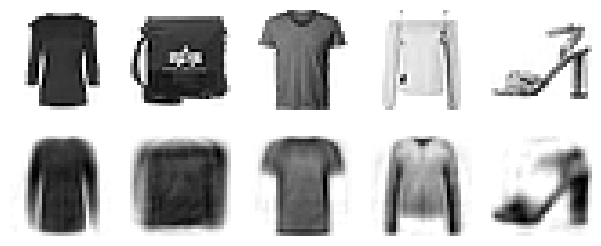

In [55]:
plot_reconstructions(X_valid_50, predicciones_0)

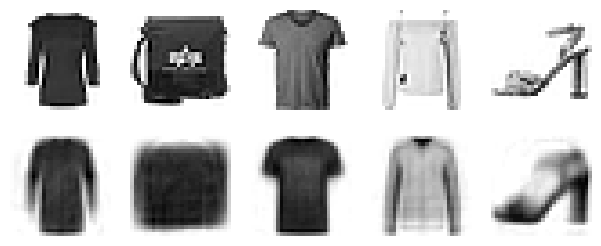

In [56]:
plot_reconstructions(X_valid_50, predicciones_1)

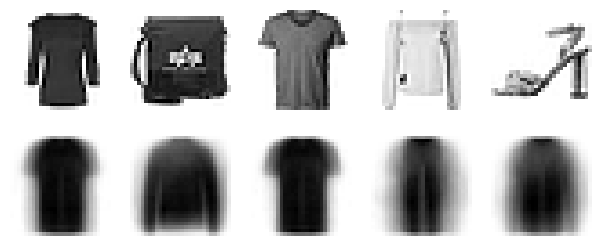

In [57]:
plot_reconstructions(X_valid_50, predicciones_gt_1_15)